### Tutorial 2 -- Radially extended JJ model

Before working with this tutorial, it is recommended to go through Tutorial 1 where the steps of producing potential-density pair and many other output quantities are described for the Solar neighbourhood. 

Here we follow the same steps, but everything is generalised for a range of moderate Galactocentric distances.

#### Setting up 

As before, we start with importing *jjmodel* classes, functions, and parameters. 
For the global model, more parameters need to be specified in the parameter file(s). Check the full parameter list and their descriptions in the manual under ```/jjmodel/docs/mydoc``` in your local *jjmodel* folder. 

In [1]:

import numpy as np 

from jjmodel.funcs import IMF
from jjmodel.constants import tp
from jjmodel.input_ import p, a, inp
from jjmodel.mwdisk import disk_builder
from jjmodel.analysis import GetPopulations
from jjmodel.populations import StellarAssemblies
from jjmodel.plotting import Plotting, PlotBlocks
from jjmodel.helpers import (IMFHandler, SFRHandler, PopHandler, 
                             ParHandler, IFMRHandler, MSAgeHandler)  



Parameter file(s) : ok.
Number of parameters =  103 , among them technical =  7

 p(run_mode=1, out_dir='tutorial2', out_mode=1, nprocess=4, Rsun=8.275, zsun=20, Vsun=12.5, Rmin=4.0, Rmax=14.0, dR=1.0, zmax=2000, dz=2, Rd=2.5, Rt=2.0, Rg1=3.0, Rg2=10, Rg10=4.0, Rg20=4.0, Rdf=9, Rf=100, a_in=-2.5, Mb=8000000000.0, sigmad=31.2, sigmat=4.9, sigmag1=1.7, sigmag2=10.9, sigmadh=51.9, sigmash=0.47, td1=0, td2=7.8, dzeta=0.58, eta=5.02, pkey=1, k_td2=1.5, k_dzeta=0.18, k_eta=-0.1, tt1=0.1, tt2=4, gamma=2, beta=3.5, imfkey=0, a0=1.04, a1=1.61, a2=2.94, a3=2.28, m0=0.5, m1=1.5, m2=6.0, dFeHdt=0, n_FeHdt=1, fehkey=1, FeHd0=-0.81, rd1=0.5, rd2=1.5, Rbr1=6.0, Rbr2=7.5, Rbr3=9.75, k1_FeHdp=-0.59, b1_FeHdp=0.85, k_alphaw=-0.43, b_alphaw=0.99, k1_t01=2.04, b1_t01=-0.32, k2_t01=-2.71, b2_t01=4.99, k3_t01=-3.91, b3_t01=7.14, k1_t02=15.89, b1_t02=-5.29, k2_t02=7.77, b2_t02=-3.04, k3_t02=-2.97, b3_t02=9.96, FeHt0=-0.94, FeHtp=0.04, rt=0.77, t0=0.97, FeHsh=-1.5, dFeHsh=0.4, n_FeHsh=7, alpha=0.409, sige=25

#### Running the model core

To build a global JJ model, the code stars from the Solar neighbourhood. 

As before, the Poisson-Boltzmann eq. is solved iteratively, and the derived self-consistent potential-density pair is used to calculate the local thin-disk half-thickness ```hdeff``` and the thick-disk scale height ```ht```. Then, all other radial bins are processed with the prescribed ```hdeff``` and ```ht``` at the new Galactocentric distance - this plays a role of 'boundary conditions'. E.g., by default, ```hdeff``` is constant at all radii, but it can be also allowed to flare (see parameters ```Rdf```, ```Rf```, and ```fkey``` in the manual on parameters). 

Also, the radial variation of SFR, AMR, and the midplane densities of the MW components are prescribed by a set of additional parameters. 


In [2]:

disk_builder(p,a,inp)


Results of this run will be saved to already existing folder output/4.0R14.0_dR1.0_tutorial2

Output directory tree created.

---Local run---



Input data saved.

Output data saved.

---Local run ended sucessfully---


---Global run---



Input data saved.

Output data saved.

---Global run ended sucessfully---

 0h 0m 1.27s


#### Creating mock stellar populations

We call the function stellar_assemblies_r() for Rsun and other radii R.
Now, when we have many radial bins, this calculation can take a bit more time 
(but still the calculation is very quick, ~5 min on 4 CPU cores for 20 R-bins with no spread in AMR).


In [ ]:

# Initialise helper classes
imf_handler = IMFHandler(p)
ifmr_handler = IFMRHandler(a)
sfr_handler = SFRHandler(p, a, inp)
pop_handler = PopHandler(p, a, inp)
msage_handler = MSAgeHandler()

# New IFMR parameters to apply
par_optim = {'ifmr':['b1','alpha1','alpha2','alpha3','m_br1','m_br2']}
params = [5.080e-01, 9.800e-02, 1.810e-01, 8.430e-02, 2.800e+00, 3.650e+00]  # pop14long_lpcode

par_handler = ParHandler(par_optim)
labels = par_handler.get_flat_param_list()
param_struct = par_handler.fill_param_struct(params)

# Define IMF ans SFR 
imf = IMF()
mass_binsc, Nmdm = imf.BPL_4slopes(p.a0,p.a1,p.a2,p.a3,p.m0,p.m1,p.m2)
imf_ref = imf.number_stars

mode_iso = {'main':'Padova','wd':'LPCODE'}
mode_label = '-'.join(mode_iso.values())
photometric_system = 'GaiaDR3'


In [4]:
def process_radius(R, sa, mode_iso, AMRd, AMRt, SFRd, SFRt, sigmaR, mass_binsc, IMF_ref):
    """Calculate and save stellar assemblies for a given radius."""

    # Generate [reference in case of WD] stellar populations
    pop_tabs_ref = sa.create_pops(R, AMRd, AMRt, SFRd, SFRt, sigmaR, imf.number_stars)

    # Apply IFMR correction only when white dwarfs are modelled
    if 'wd' in mode_iso.keys():
        # Create copies of the columns that will be modified
        pop_tabs_ref = pop_handler.create_reference_columns(
            pop_tabs_ref, ['N', 'Mini', 'age', 't_cool']
            )

        print('\tCreated reference SA tables')

        # Age and initial-mass indices
        indt, indm = pop_handler.get_age_mass_idx(pop_tabs_ref, mass_binsc)

        # White dwarf positional indices
        ind_wd = pop_handler.make_wd_idx_dict(pop_tabs_ref)

        # CMD-defined population indices
        idx_pop = pop_handler.split_into_pops(pop_tabs_ref)
        idx_pop_combined = pop_handler.combine_pops_indices(
            pop_tabs_ref, idx_pop
        )

        SFR_ref = {'d':SFRd,'t':SFRt}

        # Update number densities
        pop_tabs, indt = pop_handler.update_pop_tabs(
            param_struct,
            pop_tabs_ref,
            SFR_ref=SFR_ref,
            IMF_ref=IMF_ref,
            indt=indt,
            indm=indm,
            ind_wd=ind_wd,
            ind_pop=idx_pop_combined,
            ifmr_handler=ifmr_handler,
            msage_handler=msage_handler
        )

        print('\tApplied IFMR correction to white dwarfs')

        # Save updated tables
        mode_label = '-'.join(mode_iso.values())
        for key, table in pop_tabs.items():

            mask = np.isfinite(table['age']) & (table['age'] <= tp)
            table = table[mask]

            filename = f'{a.T["poptab"]}/SSP_R{R}_{key}_{mode_label}.csv'
            table.write(filename, overwrite=True)


In [5]:

sa = StellarAssemblies(p,a,mode_iso,photometric_system)

# Solar neighbourhood
print(f'R = {p.Rsun} kpc')

process_radius(
    p.Rsun,
    sa,
    mode_iso,
    inp['AMRd0'],
    inp['AMRt'],
    inp['SFRd0'],
    inp['SFRt0'],
    p.sigmash,
    mass_binsc,
    imf_ref
)

# Other radial bins
for i, R in enumerate(a.R):
    print(f'R = {R} kpc')

    indr = int(R // p.dR - p.Rmin // p.dR)

    process_radius(
        R,
        sa,
        mode_iso,
        inp['AMRd'][indr],
        inp['AMRt'],
        inp['SFRd'][indr],
        inp['SFRt'][indr],
        inp['SigmaR'][-1][indr],
        mass_binsc,
        imf_ref
    )

R = 8.275 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 4.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 5.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 6.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 7.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 8.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 9.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 10.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 11.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 12.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 13.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs
R = 14.0 kpc
	Created reference SA tables
	Applied IFMR correction to white dwarfs


#### Select different populations

In [7]:
# MW components to populate - tnin/thick disk and stellar halo
mw_comp = ['d', 't', 'sh']

# Prepare kwargs
kw = {'save': True}
kw_rc = {'save': True, 'fig': False, 'close': True}

R_array = [p.Rsun, *a.R]

# Population selection methods
methods = [
    ('rc_clean', kw_rc),
    ('a_stars', kw),
    ('f_stars', kw),
    ('g_dwarfs', kw),
    ('k_dwarfs', kw),
    ('white_dwarfs', kw),
]

for R in R_array:
    print(f'R = {R} kpc')

    pop = GetPopulations(mode_iso, R, p, a)

    for comp in mw_comp:
        for method_name, kwargs in methods:
            getattr(pop, method_name)(comp, **kwargs)

R = 8.275 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 4.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 5.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 6.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 7.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 8.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 9.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 10.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 11.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 12.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 13.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.
R = 14.0 kpc
	 t   : A-type stellar sample is empty.
	 t   : F sample is empty.


### Plotting

From here, we begin with the in-built visualisation of the input and output.

As before, the notations are:

    MW stellar components:                          Stellar populations:
    'd'   = thin disk                               'a'            = A stars 
    't'   = thick disk                              'f'            = F stars
    'sh'  = stellar halo                            'rc' or 'rc+'  = RC stars
    'dt'  = thin + thick disk                       'gdw'          = G dwarfs
    'tot' = thin + thick disk + stellar halo        'kdw'          = K dwarfs

#### Model input: SFR, radial density profiles, and disk thickness

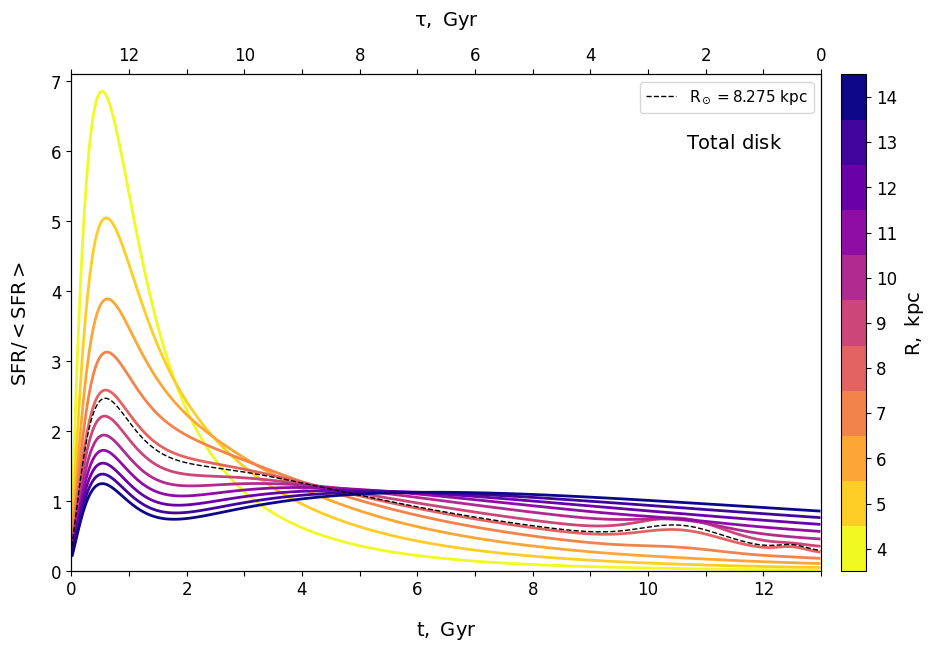

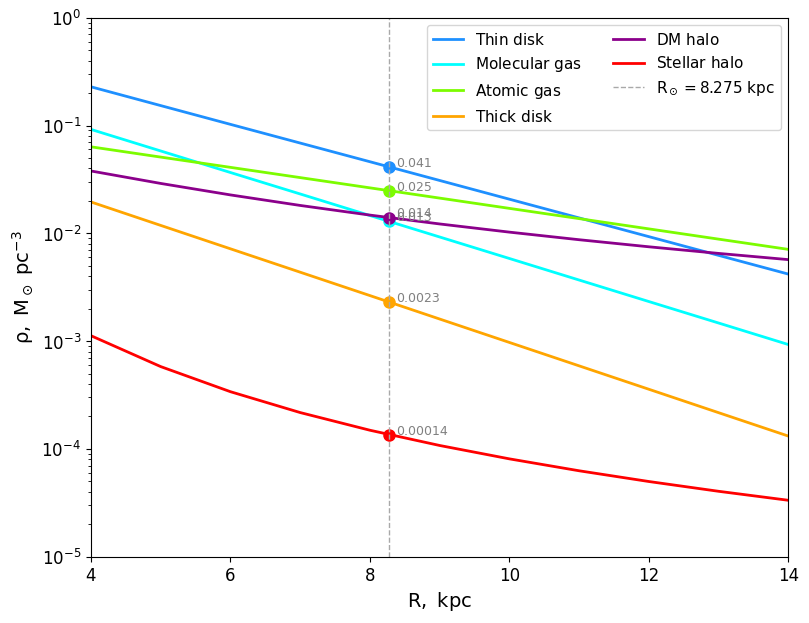

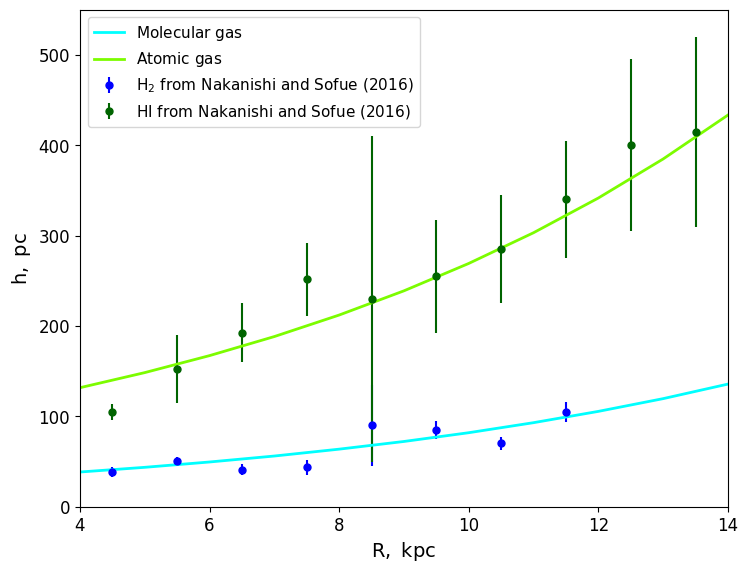

In [3]:

P = Plotting(p,a,inp)  

# Assumed variation of SFR with R for the disk (thin and thick):
P.nsfr_plt('dt',cbar_bins=True,cbar='plasma_r')    

# Assumed radial density profiles of the MW components:
P.rhor_plt()

# Assumed profiles of the gas scale heights (data from Sofue):
P.hr_gas_plt();


#### Model input: AMR and mass loss

##### On the assumed radia variation of mass loss function $g$

$g(R)$ is consistent with the adopted age-matallicity relation, AMR(R), and corresponds to the four-slope broken power law (4BPL) IMF with parameters from Sysoliatina and Just (2021) (see manual about parameters for more details). 

If you change the AMR, also the mass loss will be adapted to keep the consistency. 

If the IMF is changed, then, strictly speaking, $g(R)$ needs to be recalculated as well (with the new IMF and e.g. the chemical evolution code *Chempy*). But in practice, a variation of the IMF influences $g(R)$ only weakly. Also, $g(R)$ is itself one of the least important input functions of the JJ model in terms of the impact on the potential and density profiles. Therefore, it is quite safe to use the provided grid of the mass loss coefficients calculated for the 4BPL IMF (```jjmodel/input/mass_loss```) also with other IMF shapes.


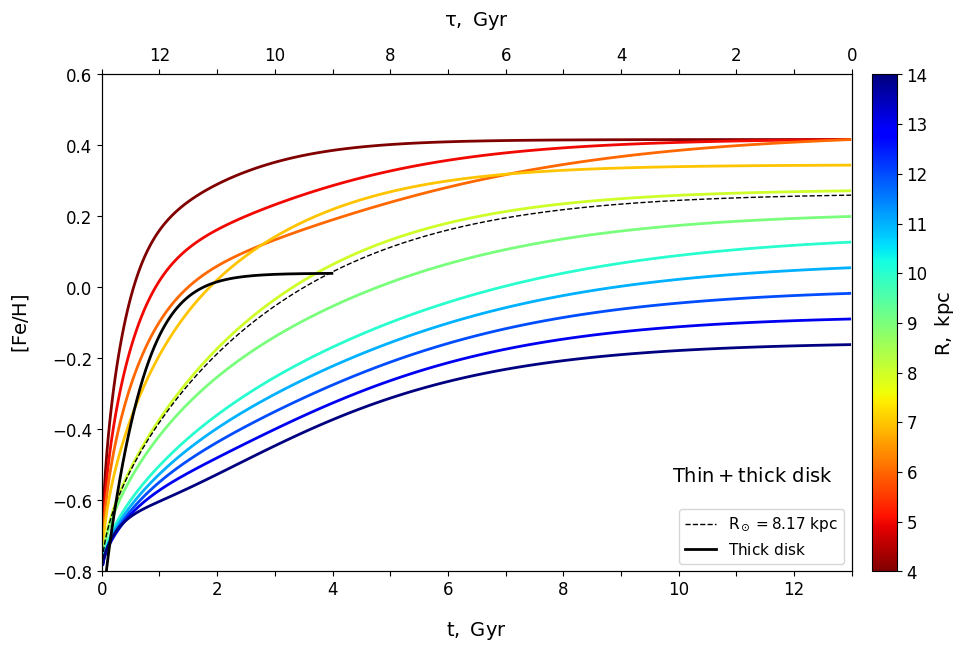

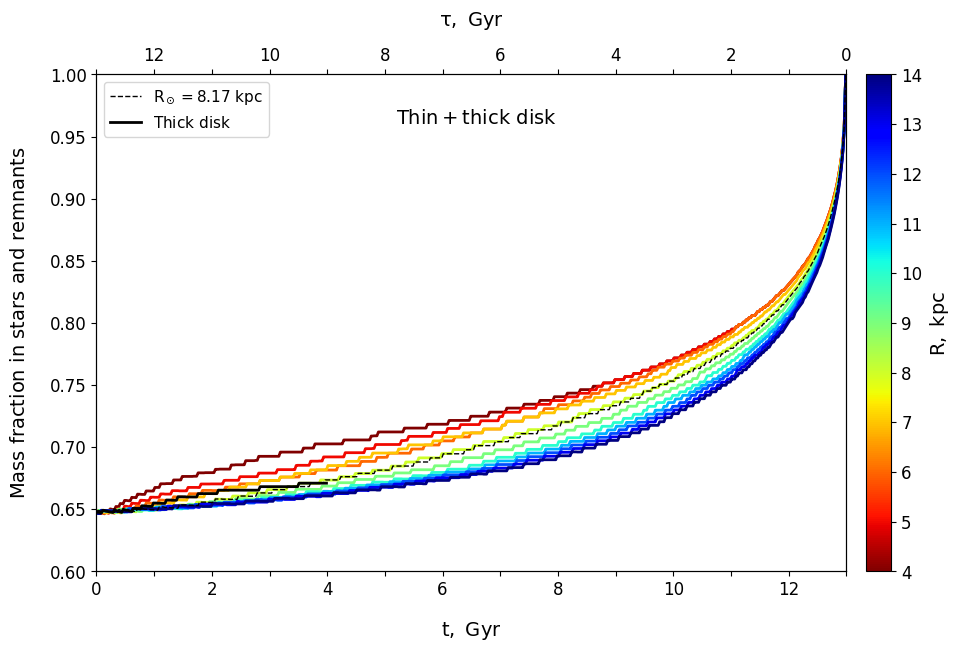

In [12]:

# Age-metallicity relation for the disk
P.amrr_plt('dt')   

# Mass loss function corresponding to it
P.gr_plt('dt');


#### Potential and vertical force

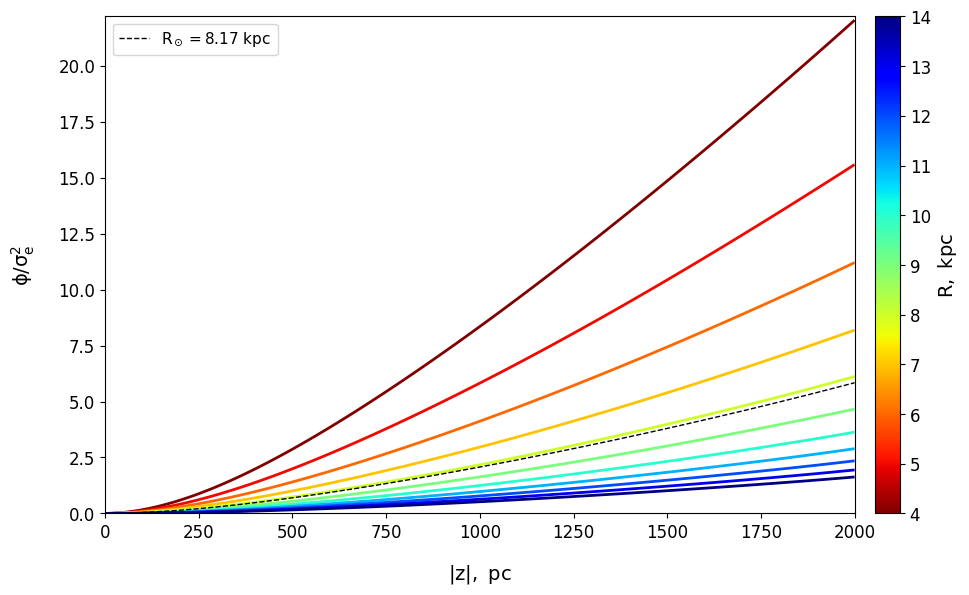

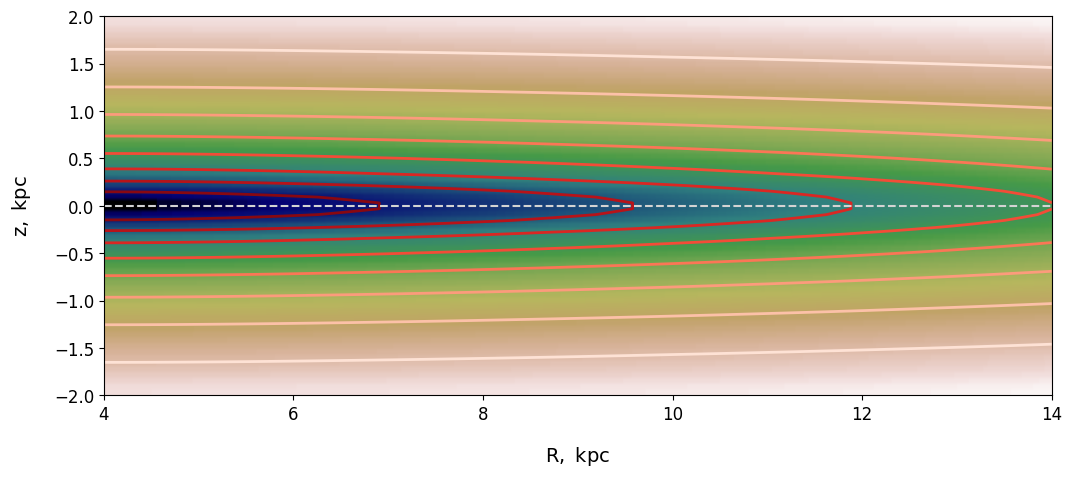

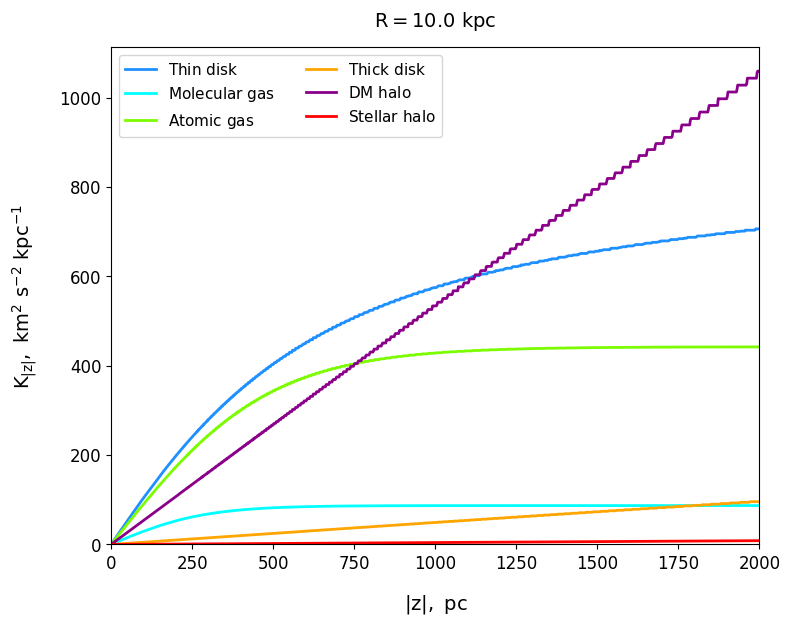

In [13]:

# Normalized vertical potential at the different R:
P.fi_plt()            

# Iso-potential lines in Rz-plane:
P.fi_iso_plt()              

# The vertical force for some radius:
radius = 10.0  # kpc
P.kz_plt(radius);


#### Vertical density profiles

Density profiles can be plotted at the different radii, for different populations, and 
in the age and metallicity bins. 

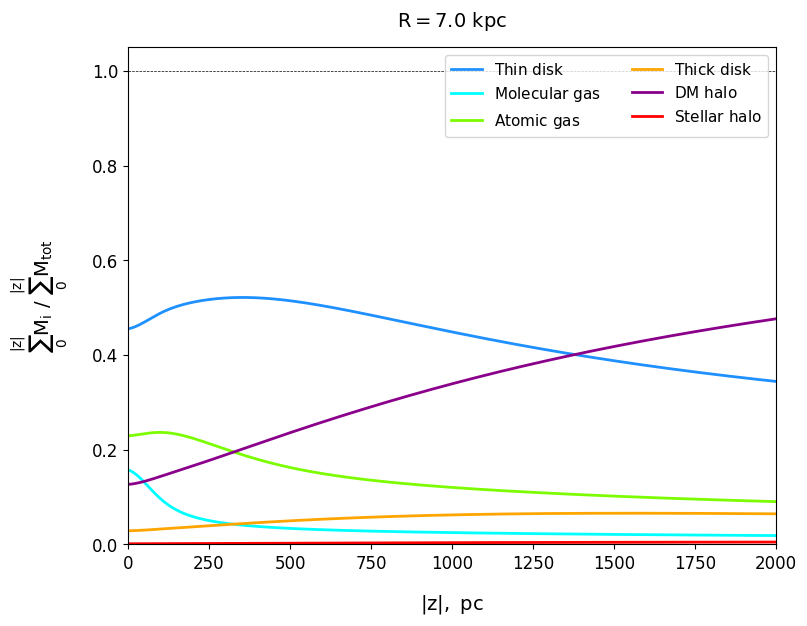

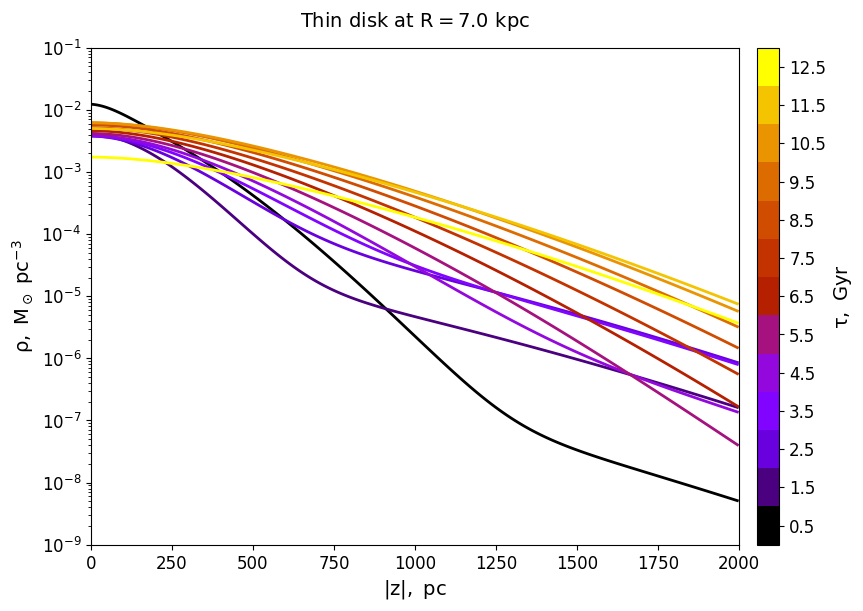

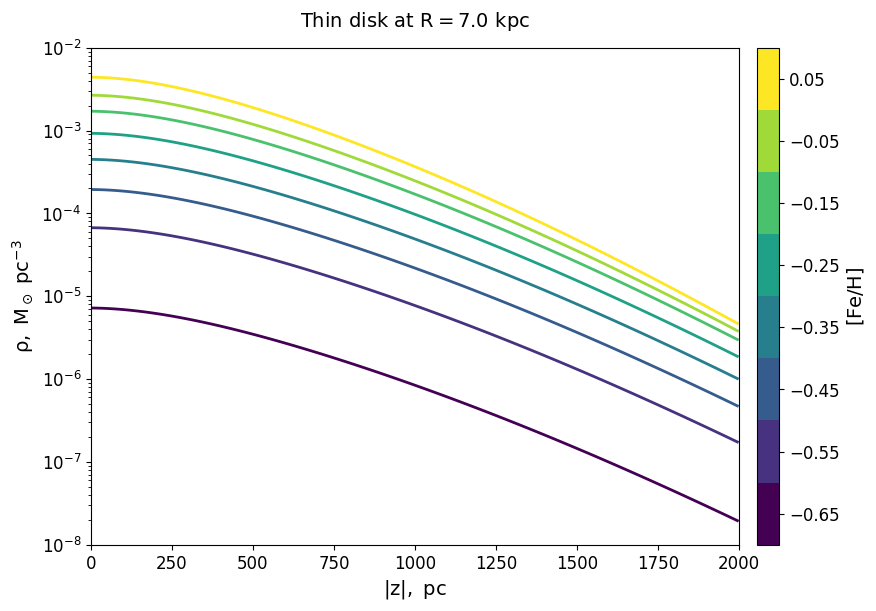

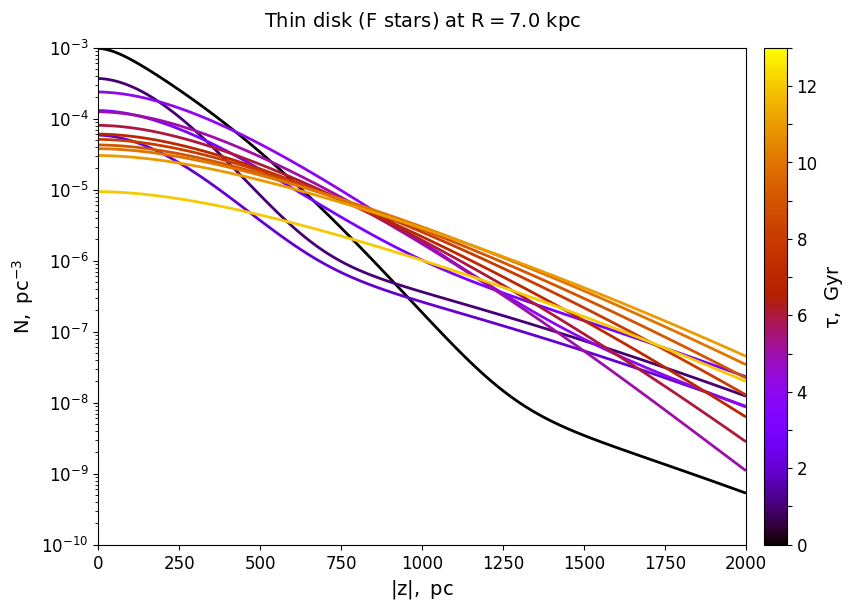

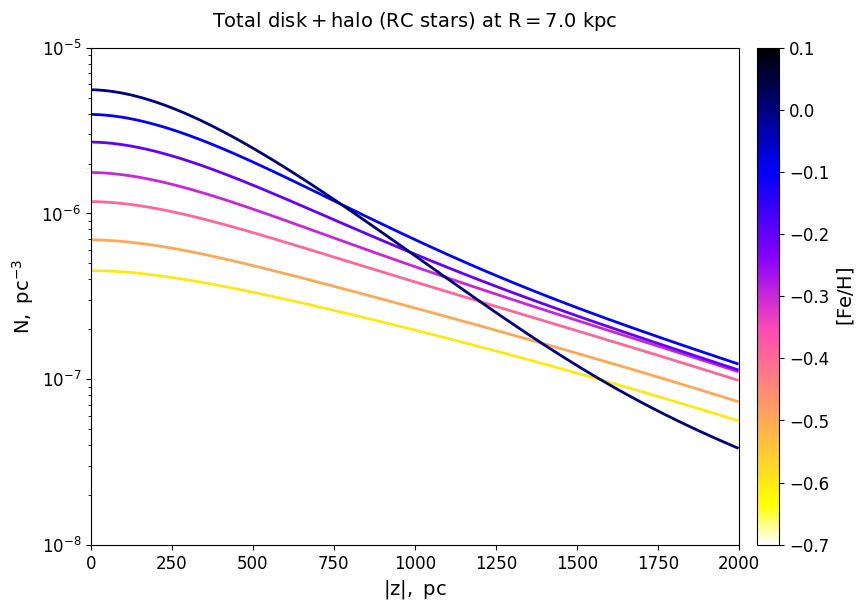

In [4]:

radius = 7.0                               # kpc, Galactocentric distance
ages = np.arange(0, tp + 1, 1)             # Gyr, age bins
mets = np.arange(-0.7, 0.2, 0.1)           # dex, metallicity bins

# Overall vertical density profiles (test parameters 'normalized' and 'cumulative'):
P.rhoz_plt(radius,cumulative=True)

# Thin disk, age bins:
P.rhoz_monoage_plt('d',radius,ages,between=True,cbar_bins=True)

# Thin disk, metallicity bins:
P.rhoz_monomet_plt('d',radius,mets,cbar_bins=True,cbar='viridis');

# Try some more special cases:
kw = {'mode_iso':mode_iso}
P.rhoz_monoage_plt('d',radius,ages,between=True,mode_pop='f',number=True,**kw);
P.rhoz_monomet_plt('tot',radius,mets,mode_pop='rc',number=True,**kw);


#### Vertical density profiles for a custom population

It is also possible to pass a custom table for plotting. For example, can we select some population
consisting of the thin-disk stars and defined with special cuts. 

Then we plot vertical profiles using the parameter ```tab```.
Note, that the model_component argument for ```Plotting.rhoz_monoage_plt()``` must be the same one that has been used to select the population. More examples on defining custom populations and using the keyword tab can be found in Tutorial 3. 

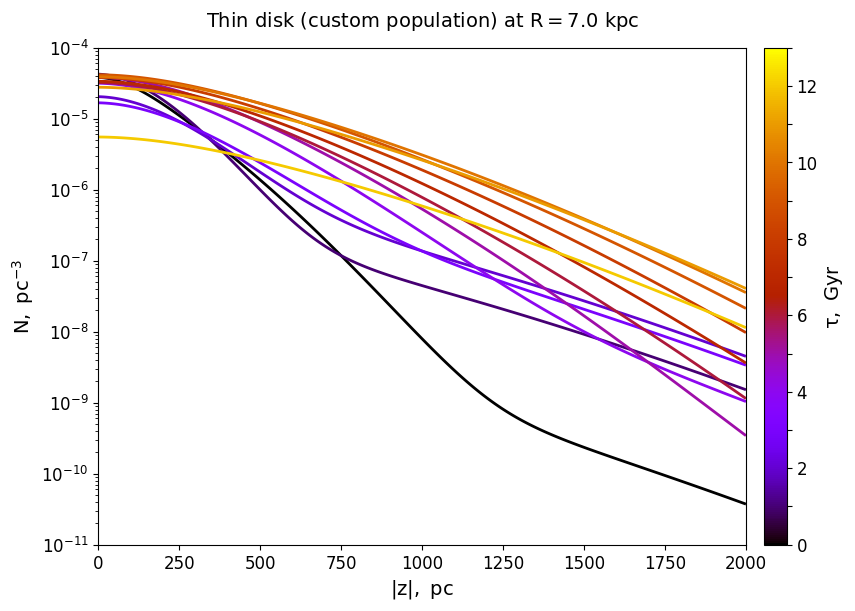

In [5]:
# New population 

model_component = 'd'

pop = GetPopulations(mode_iso,radius,p,a)

tab_custom_d = pop.custom_population(
    model_component,                            # MW component to select
    ['logT','logg'],                            # Columns for the cut
    [[np.log10(4e3),np.log10(5e3)],[2.5,4.5]]   # Ranges for the columns
    )  

# Profiles
P.rhoz_monoage_plt(model_component,radius,ages,between=True,tab=tab_custom_d,number=True);


#### Radial density profiles

The overall radial density profiles of the disk, gas, halo, etc. constitute the model input (see plot above). 

But with the vertical potential now known at each R, we can get a more detailed picture: 
calculate radial densities of the MW components or populations in age or metallicity bins and in z-slices. 

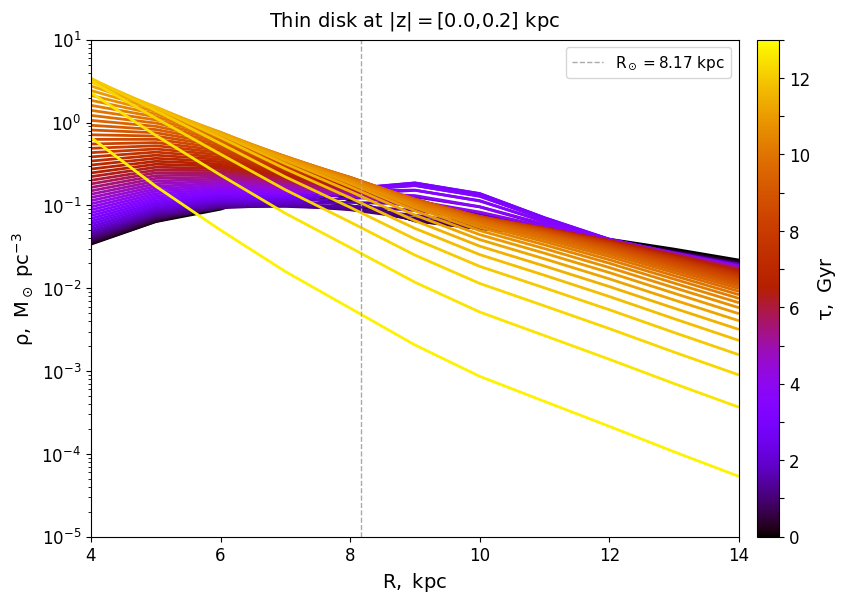

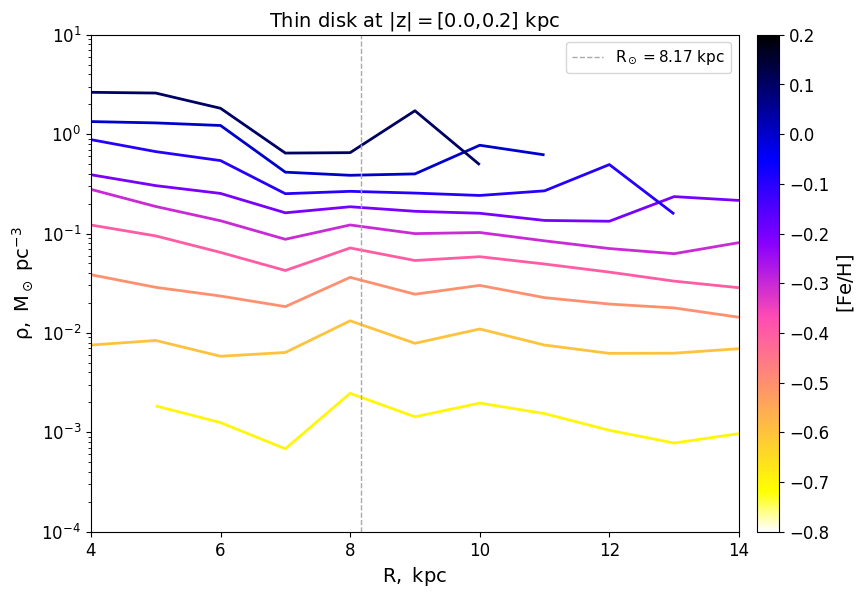

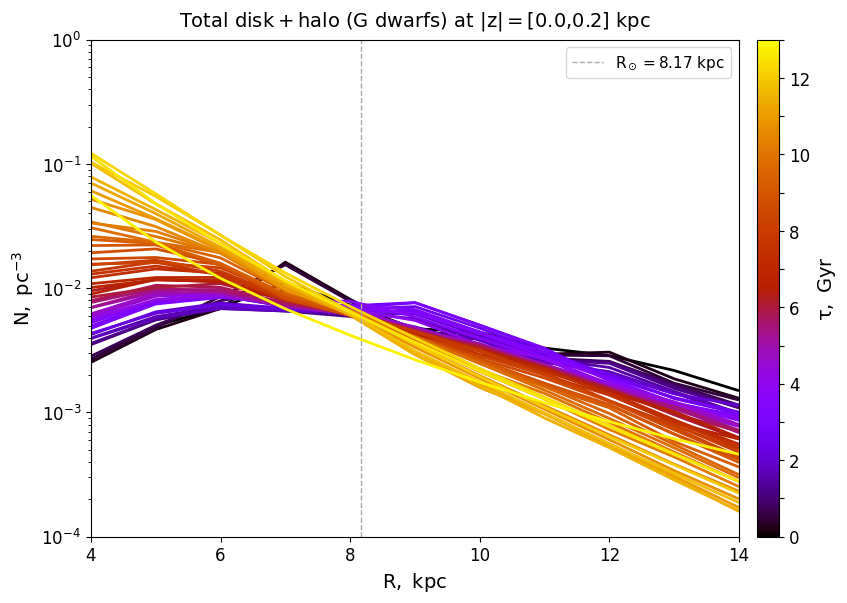

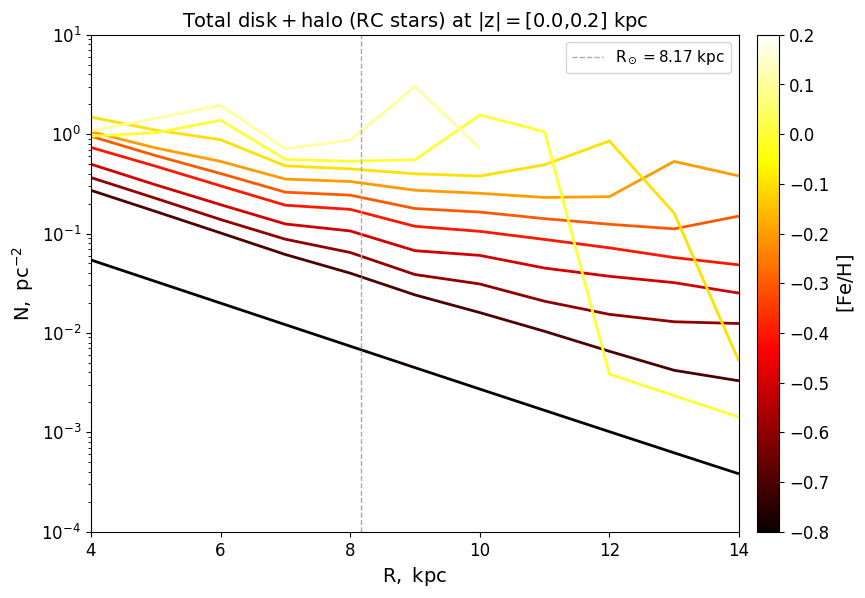

In [6]:

z_slice = [0, 200]                          # pc,  range of heights
ages = np.arange(0, tp + 0.25, 0.25)        # Gyr, ages bins
mets = np.arange(-0.8, 0.3, 0.1)            # dex, metallicity bins


# Thin-dsik mono-age populations (if sigma=True, surface density profiles are plotted): 
f, ax = P.rhor_monoage_plt('d',z_slice,ages,between=True,**kw)  
#ax.set_ylim(1e-4,10)        

# By analogy, for metallicity bins do:
P.rhor_monomet_plt('d',z_slice,mets)

# Try more special input:
P.rhor_monoage_plt('tot',z_slice,ages,between=True,mode_pop='gdw',number=True,**kw);
P.rhor_monomet_plt('tot',z_slice,mets,mode_pop='rc',number=True,sigma=True,cbar='hot',**kw);


#### Age gradients and distributions

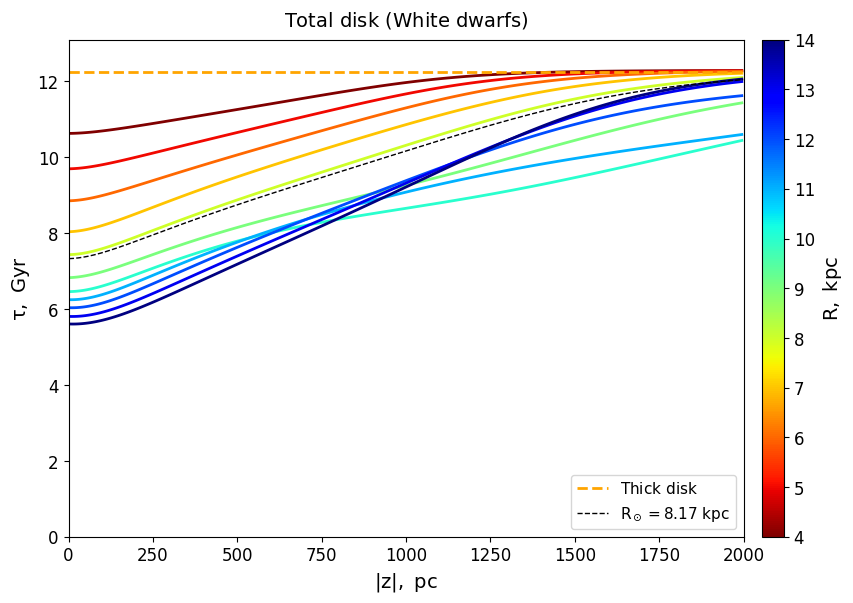

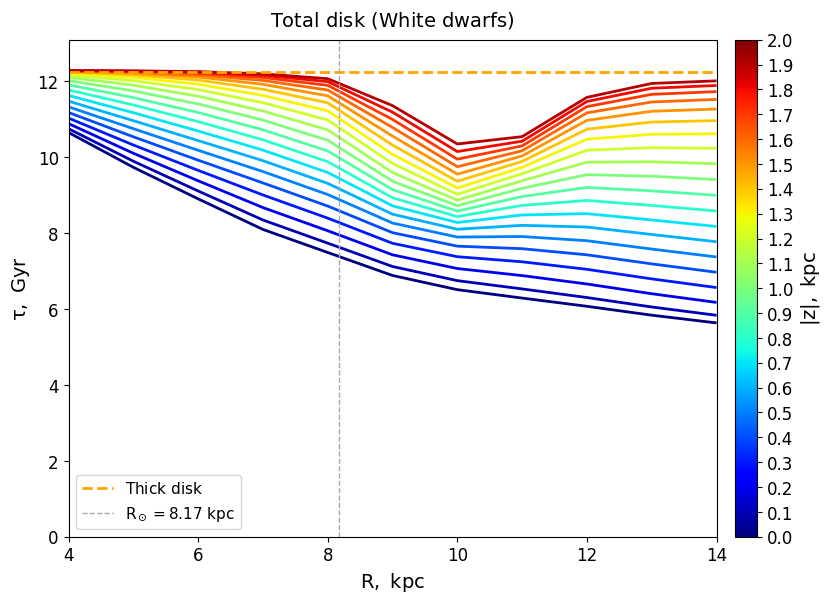

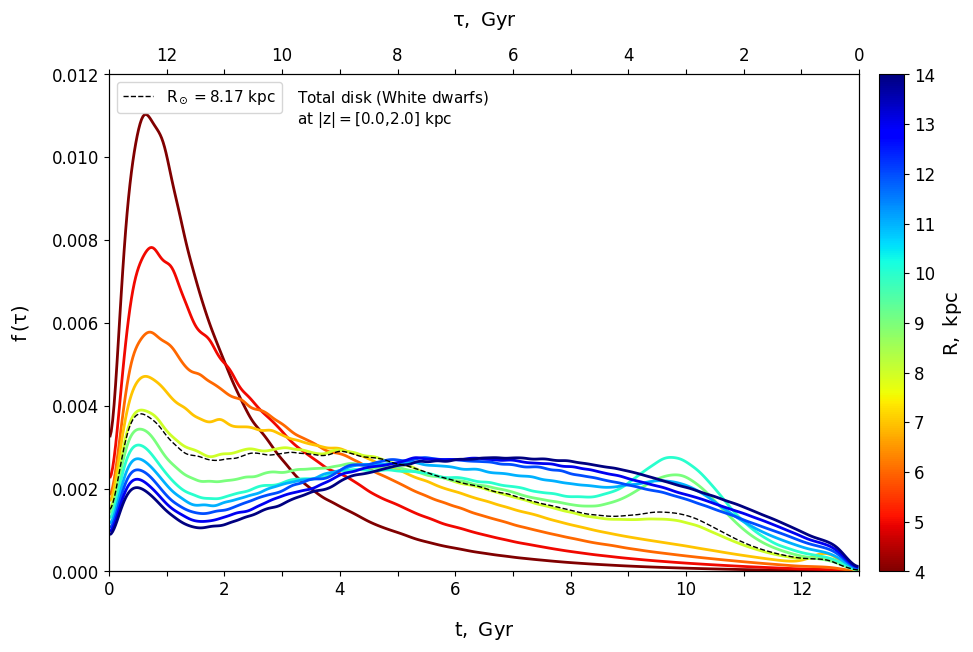

In [7]:

# Vertical profiles of the mean age:
P.agez_plt('dt',mode_pop='wd',number=True,**kw)

# Some quantities, like the radial age profiles, can be plotted for a set of z-slices (z-bins):
z_slices = np.arange(0, p.zmax + 100, 100)     # pc
P.ager_plt('dt',z_slices,mode_pop='wd',number=True,**kw)

# To see the age distributions in some horizontal z-slice at the different R, do 
# (here we look at the RC stars; ages are weighted with the number density, not matter density; 
# sigma_gauss=0.05 defines the width of the Gaussian kernel used to smooth the distributions):
P.agehist_plt('dt',[z_slices[0],z_slices[-1]],mode_pop='wd',number=True,sigma_gauss=0.1,**kw);


#### Metallicity gradients and distributions

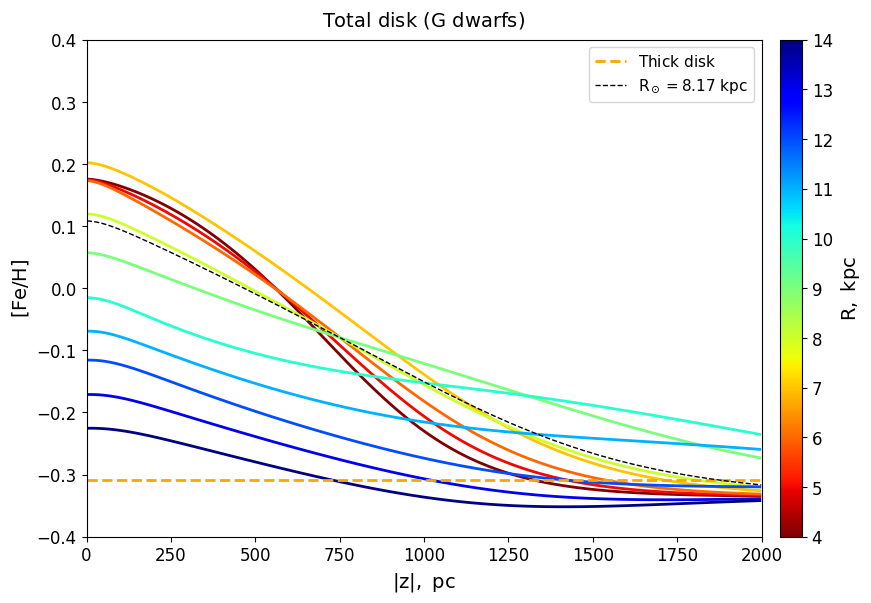

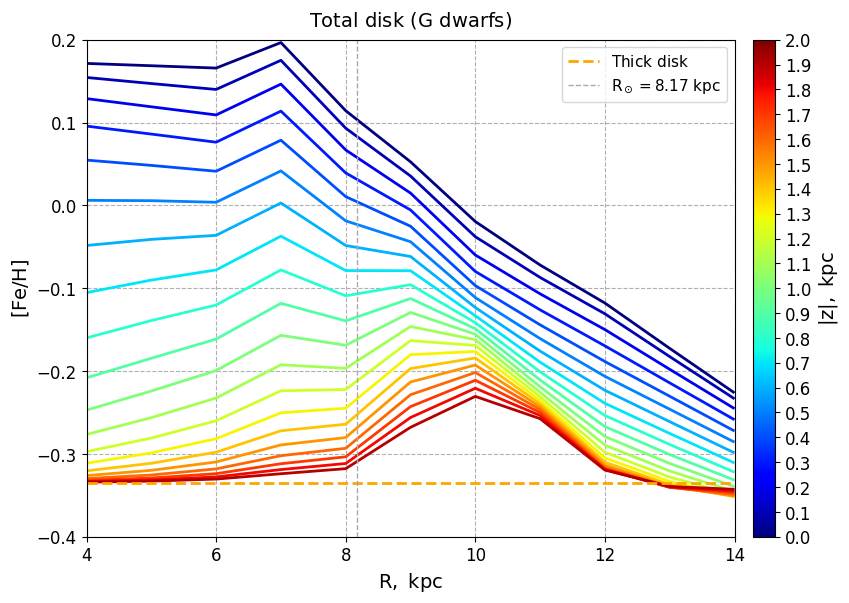

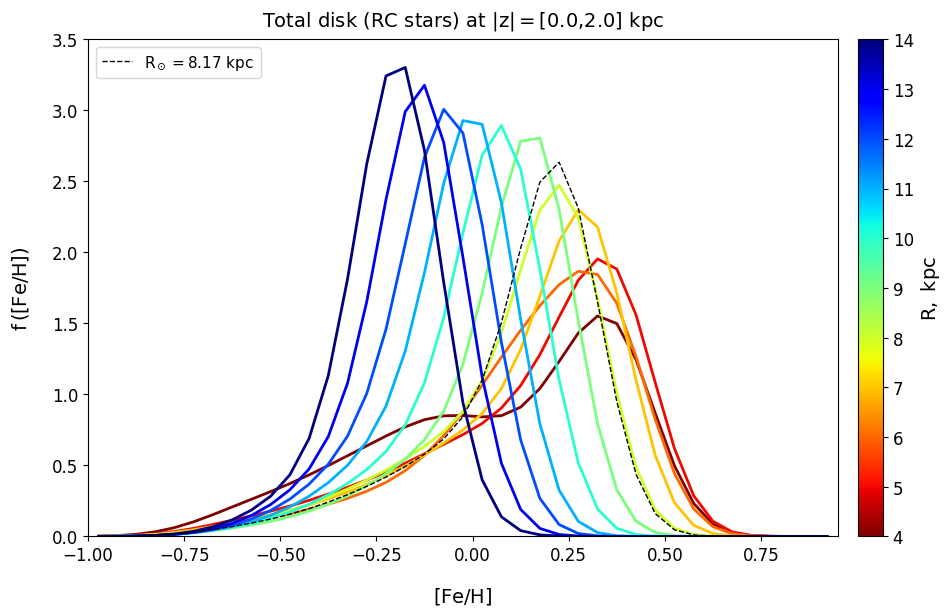

In [9]:

# Vertical profiles of the mean metallicities:
P.metz_plt('dt',mode_pop='gdw',number=True,**kw)

# Radial metallicity gradient in z-bins: 
z_slices = np.arange(0, p.zmax + 100, 100)     # pc
f, ax = P.metr_plt('dt',z_slices,mode_pop='gdw',number=True,**kw)
ax.grid(linestyle='--') 

# Metallicity distributions across R bins: 
P.methist_plt('dt',[z_slices[0],z_slices[-1]],mode_pop='rc',number=True,
              sigma_gauss=0.1,metbins=np.arange(-1.0,1.0,0.05),**kw);


##### Scale heights

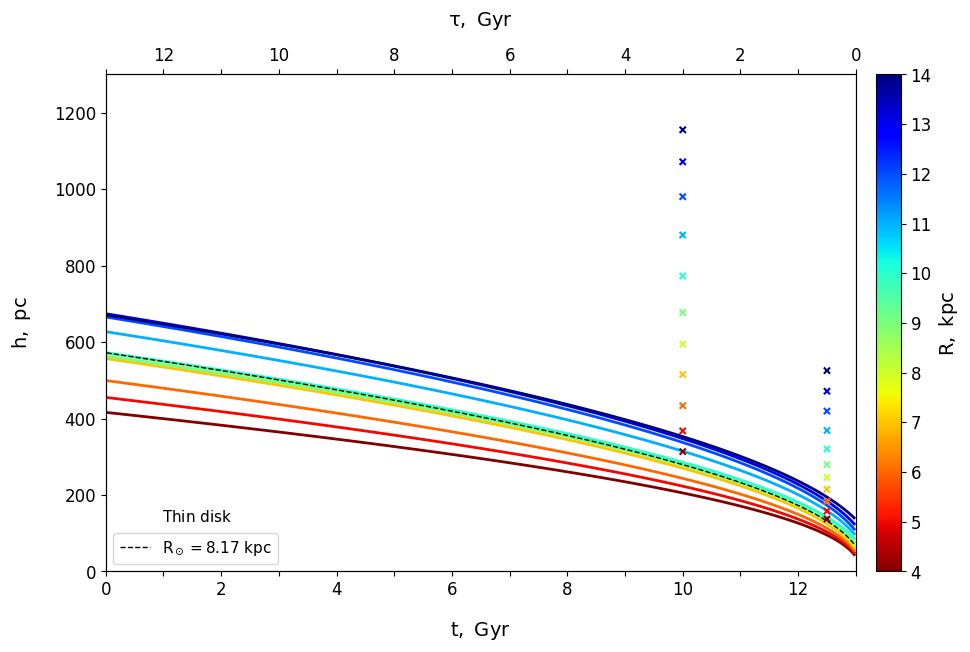

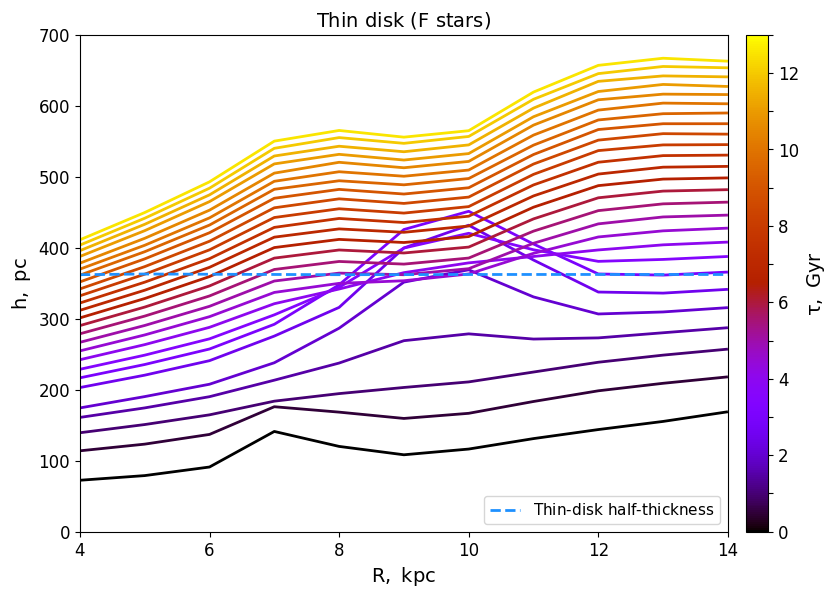

In [10]:

# Scale heights of the thin-disk mono-age subpopulations.
# As before, special subpopulations are marked with crosses.
P.h_plt()

# We may also want to look at the radial change of scale height of some population
# (which can differ from the overall disk thickness):
P.hr_monoage_plt('d',np.arange(0, tp + 0.5, 0.5),between=True,mode_pop='f',number=True,**kw);


#### Age-velocity dispersion relation and $\sigma_W$ vertical gradient


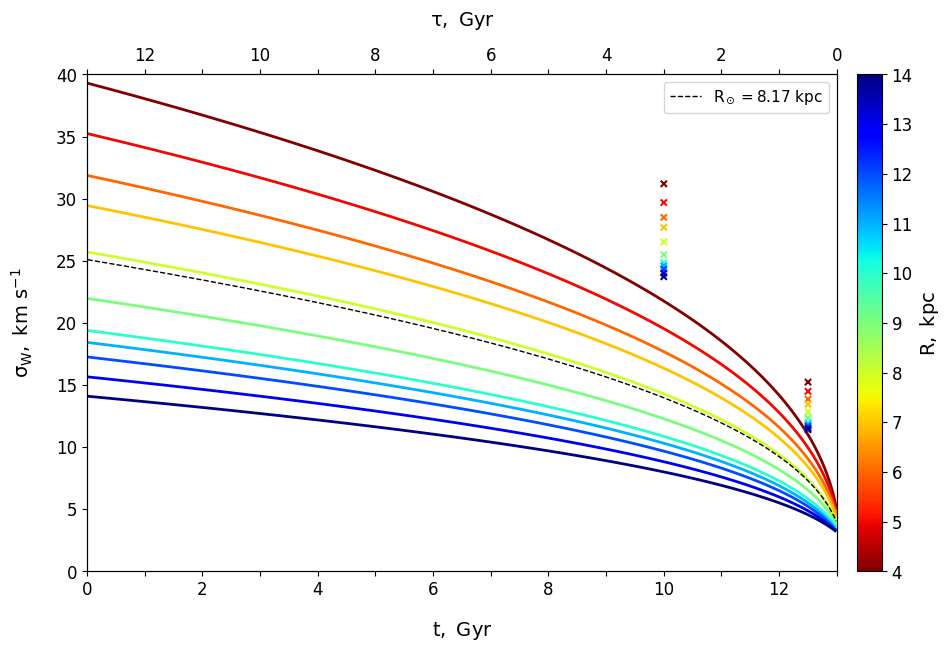

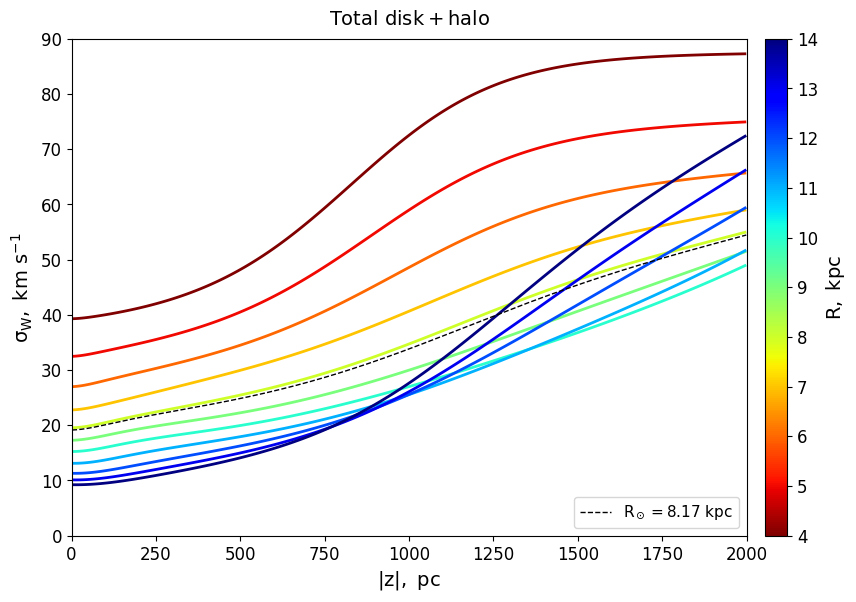

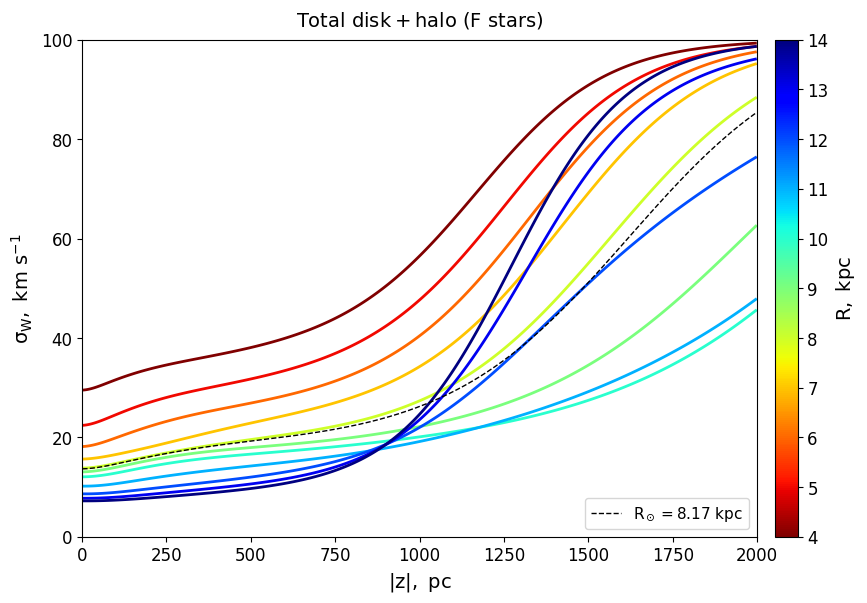

In [ ]:

# AVR:
P.avr_plt()

# Vertical profile of the W-velocity dispersion:
P.sigwz_plt('tot');

# Try also something special and compare to the overall profile of the W-velocity dispersion:
#P.sigwz_plt('tot',mode_pop='f',number=True,**kw);


#### Radial profiles of $\sigma_W$

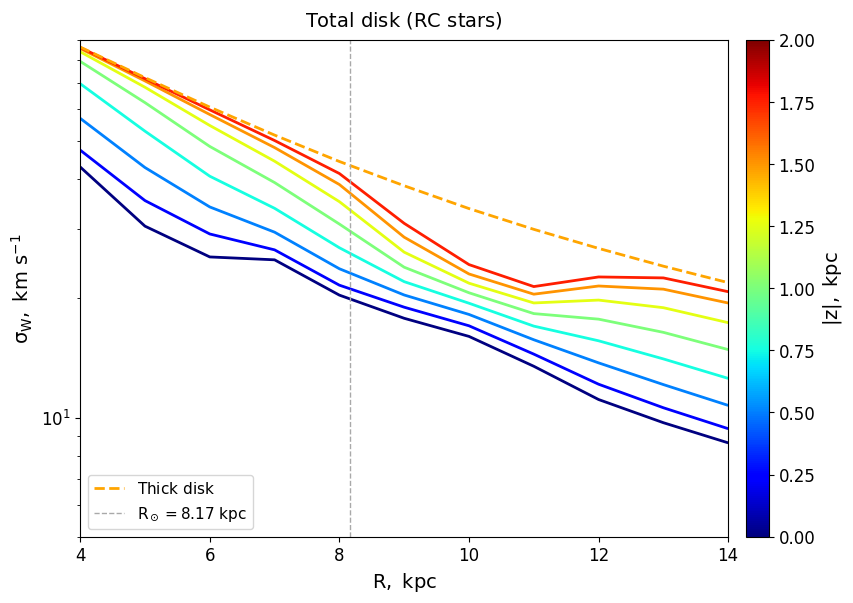

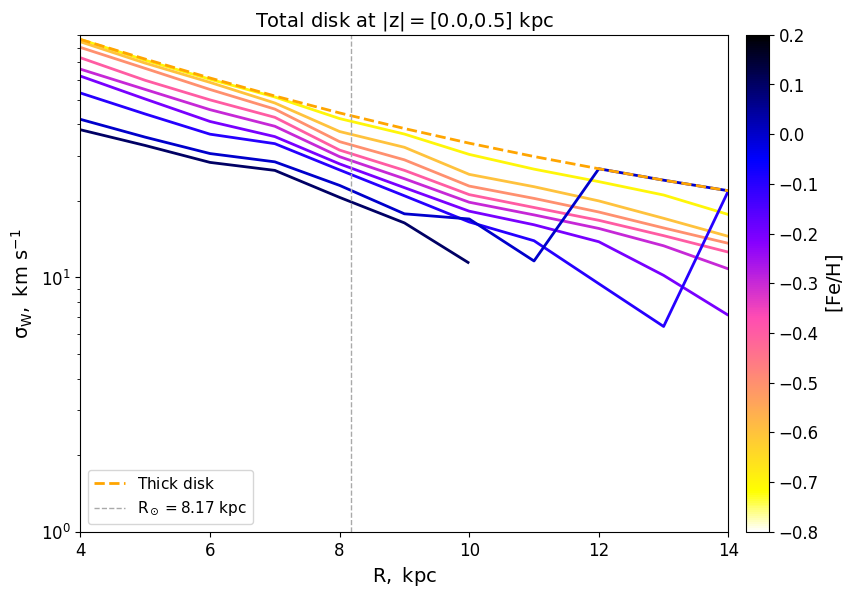

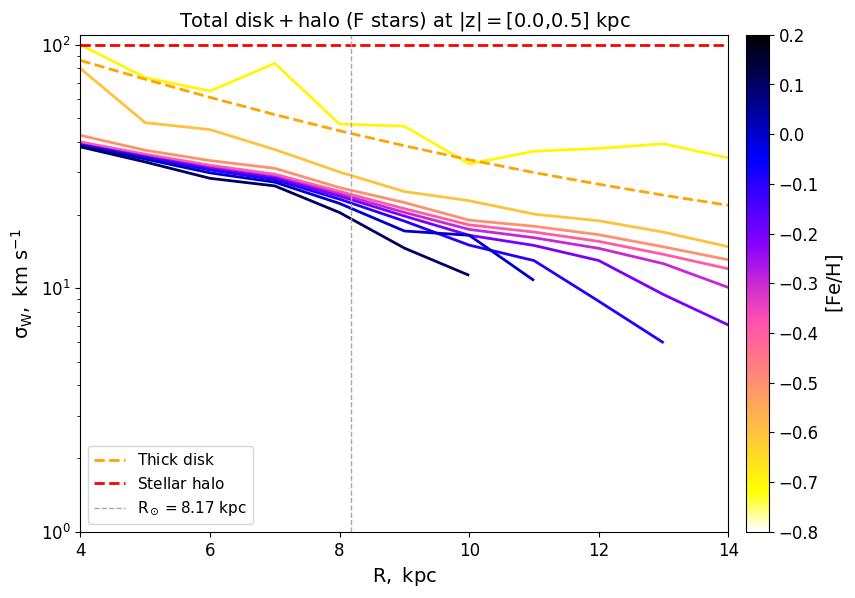

In [7]:

z_slices = np.arange(0, p.zmax + 250, 250)  # pc

# Radial profiles of the W-velocity dispersion for all disk stars:
P.sigwr_plt('dt',z_slices,mode_pop='rc',number=True,**kw) 

# For a special population try:
#P.sigwr_plt('dt',z_slices_set,mode_pop='rc',number=True) 

# For a single z-slice, W-velocity dispersion can be plotted in age- and metallicity-bins.
z_slice = [0,500]                          # pc,  range of heights
mets = np.arange(-0.8, 0.3, 0.1)             # dex, set of metallicities

P.sigwr_monomet_plt('dt',z_slice,mets)

# Or try other examples:
P.sigwr_monomet_plt('tot',z_slice,mets,mode_pop='f',number=True,**kw);

# And for age-bins:
#ages = np.arange(0, tp + 0.25, 0.25)           # Gyr, age bins
#P.sigwr_monoage_plt('dt',z_slice,ages)
#P.sigwr_monoage_plt('tot',z_slice,ages,mode_pop='f',number=True,between=True,**kw) 

# Also, let's check the resulting W-velocity dispersion of the two gas components:
#P.sigwr_gas_plt();


#### $W$-velocity distributions

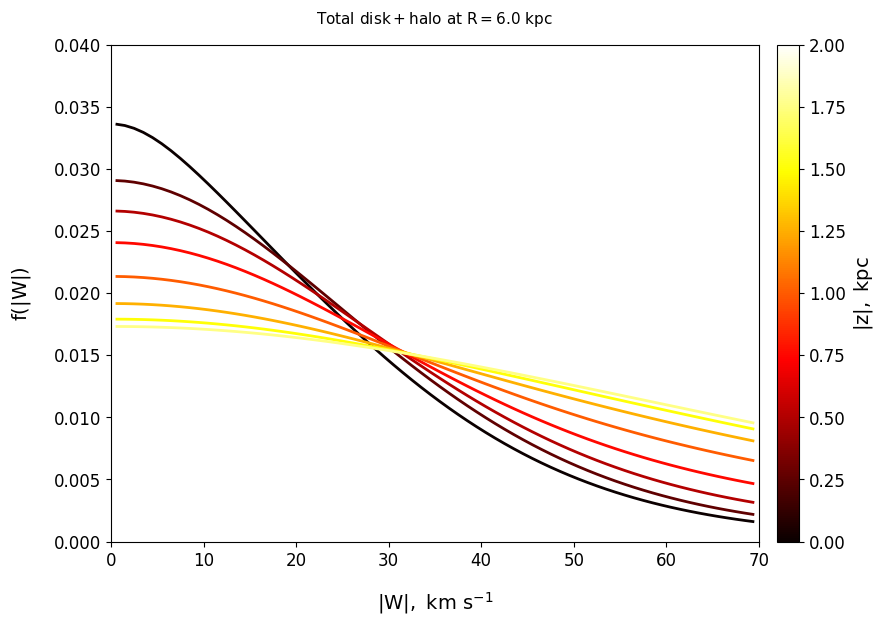

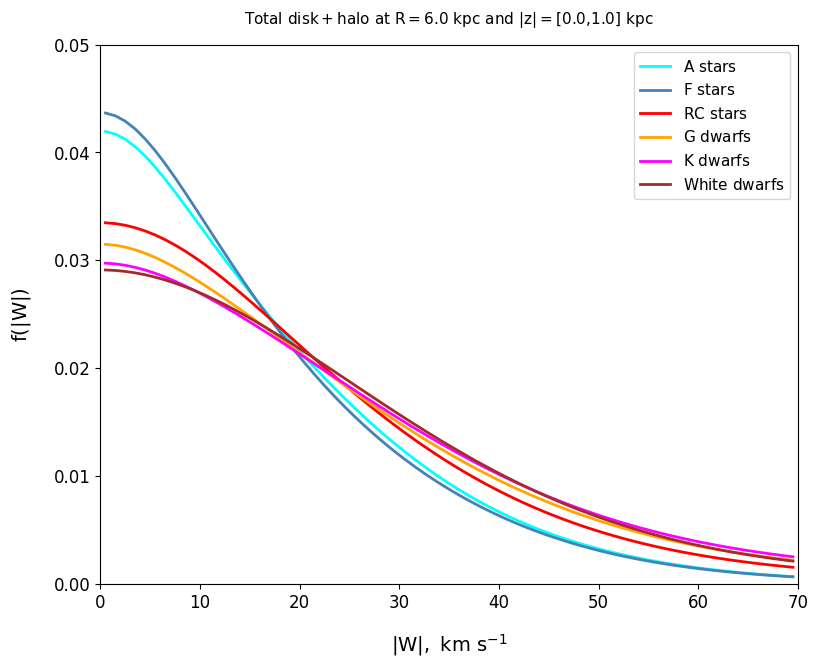

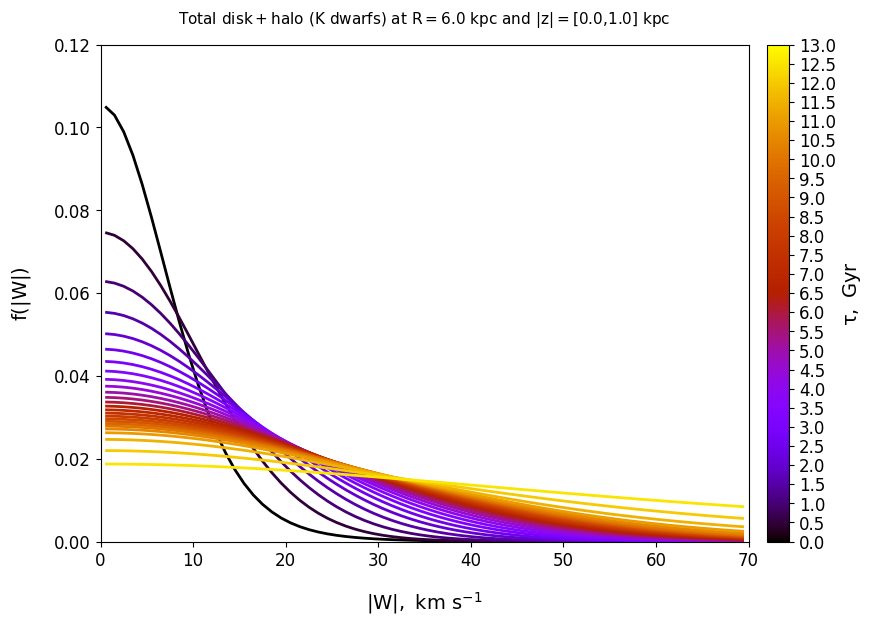

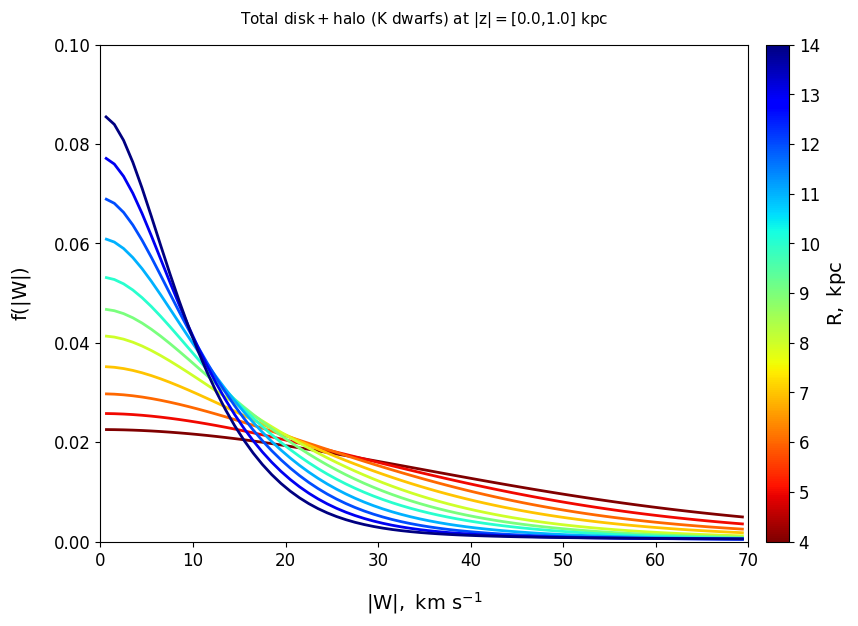

In [17]:

radius = 6.0                                # kpc
z_slice = [0, 1000]                         # pc
z_slices = np.arange(0, p.zmax + 250, 250)  # pc
ages = np.arange(0, tp + 0.5, 0.5)          # Gyr
mets = np.arange(-1, 0.4, 0.1)              # dex
w_max, delta_w = 70, 1                      # km/s


# Fixed R and different z:
P.fw_hist_plt('tot',radius,z_slices,wmax=w_max,dw=delta_w,cbar='hot')

# Fixed R, single z-bin, different populations:
pop_list = ['a','f','rc','gdw','kdw','wd']
P.fw_hist_plt('tot',radius,z_slice,mode_pop=pop_list,number=True,wmax=w_max,dw=delta_w,**kw)

# Fixed R, single z-bin, single population, different ages or metallicities:
P.fw_hist_plt('tot',radius,z_slice,ages=ages,mode_pop='kdw',number=True,wmax=w_max,dw=delta_w,**kw)
#P.fw_hist_plt('tot',radius,z_slice,mets=mets,mode_pop='kdw',number=True,wmax=w_max,dw=delta_w,**kw)

# Different R, single z-bin, single population:
P.fw_hist_plt('tot',a.R,z_slice,mode_pop='kdw',number=True,wmax=w_max,dw=delta_w,**kw);

# We can also add a cut on age or metallicity:
#P.fw_hist_plt('tot',a.R,z_slice,ages=[0,6],mode_pop='kdw',number=True,wmax=w_max,dw=delta_w,**kw)
#P.fw_hist_plt('tot',a.R,z_slice,mets=[-0.6,-0.2],mode_pop='kdw',number=True,wmax=w_max,dw=delta_w,**kw)


#### Rotation curve

This is in fact model input because the rotation curve follows from the assumed radial matter distribution. 

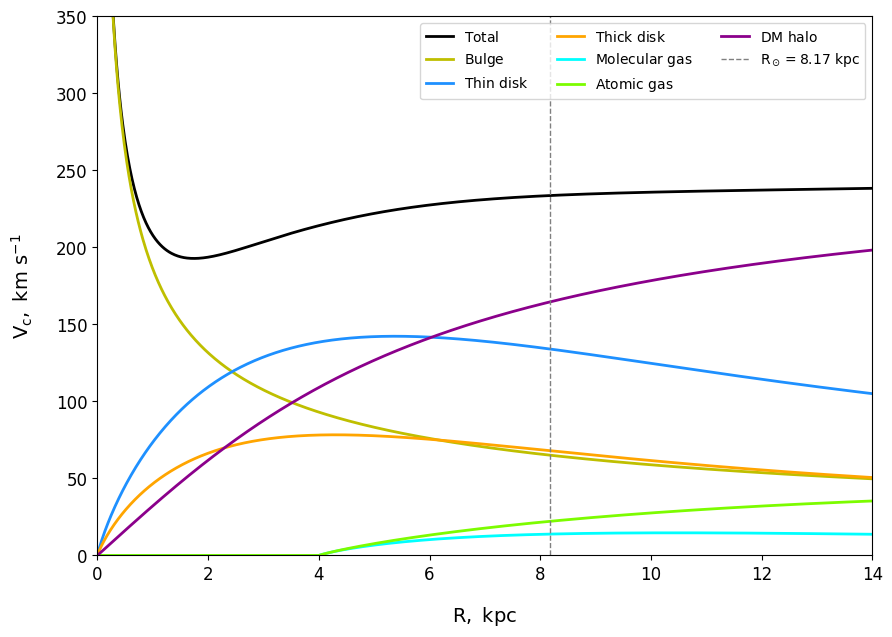

In [18]:

# MW rotation curve:
P.rot_curve_plt();


#### $R-z$ density maps


Density maps in the $R-z$ plane help to visualise the overall distribution of stars or their properties across the disk. 


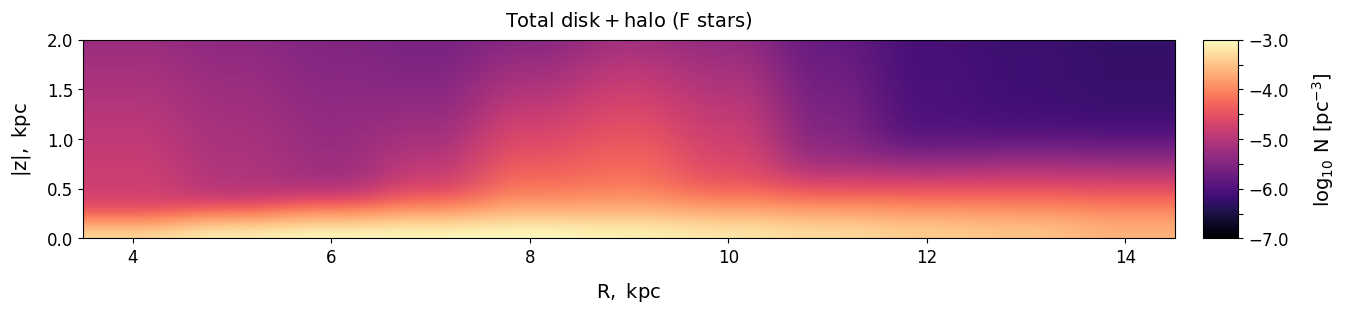

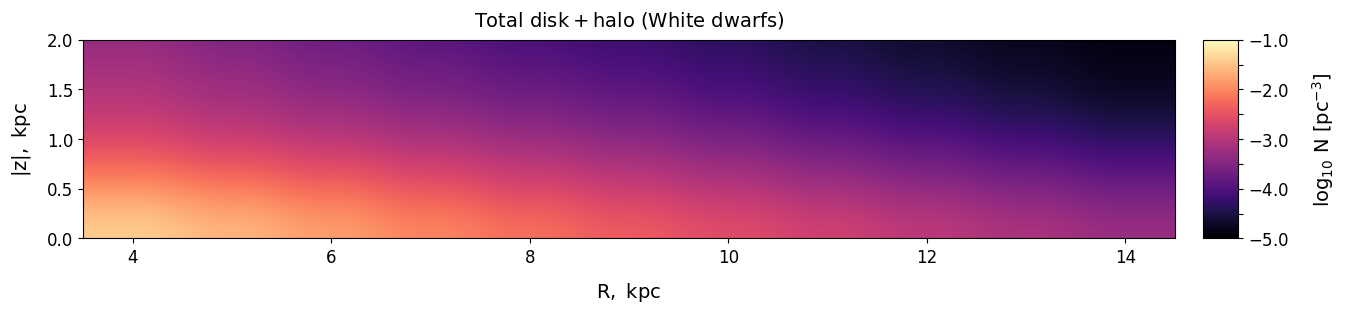

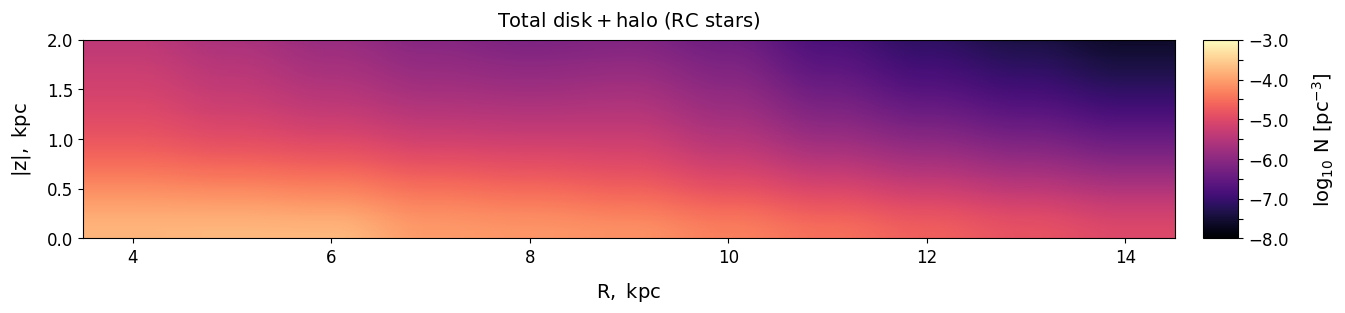

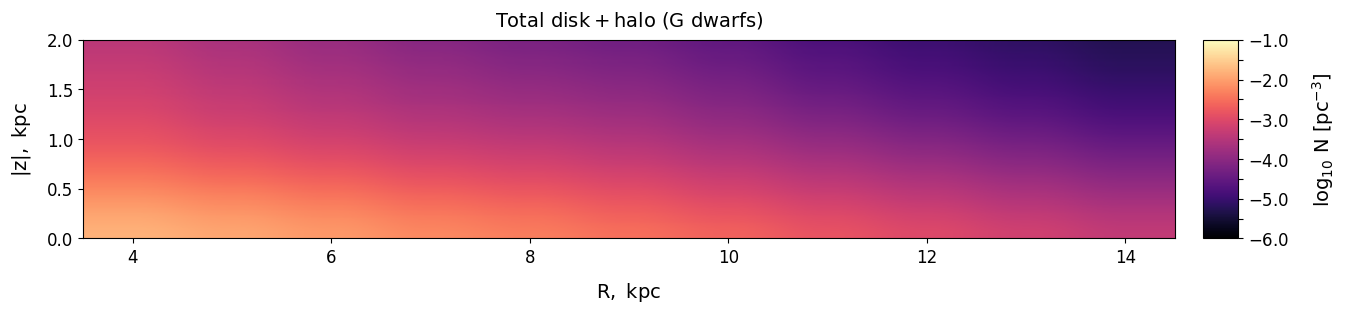

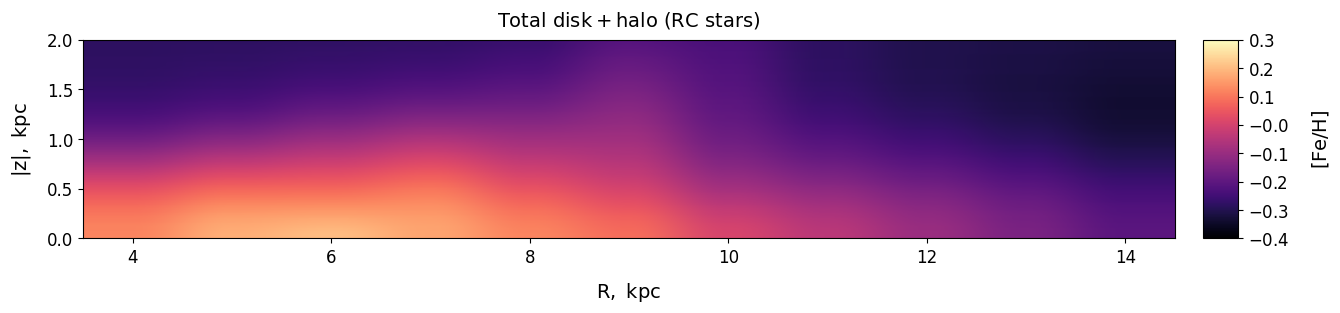

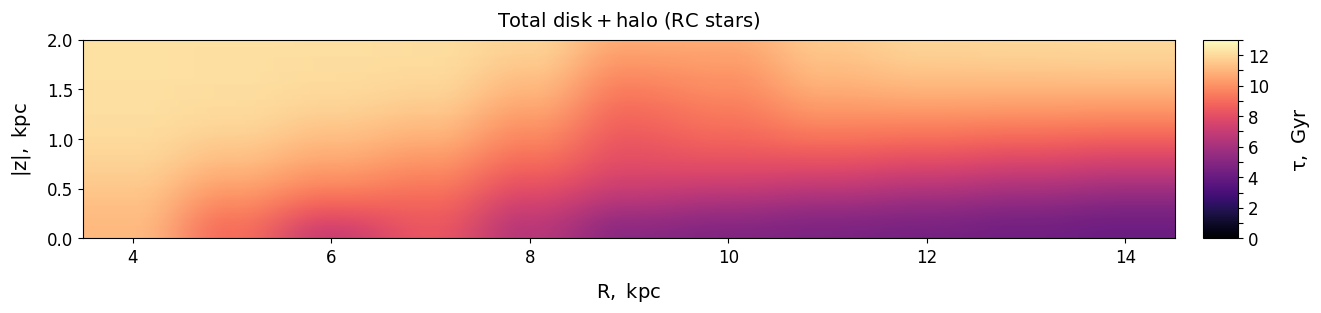

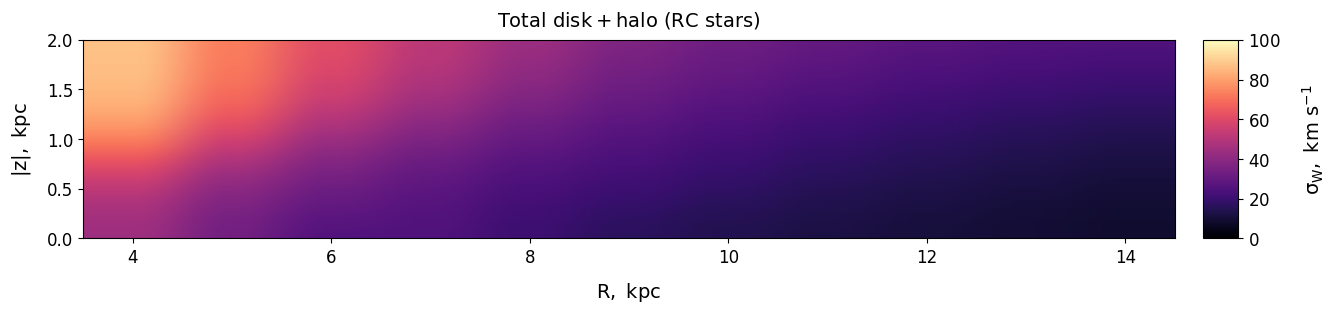

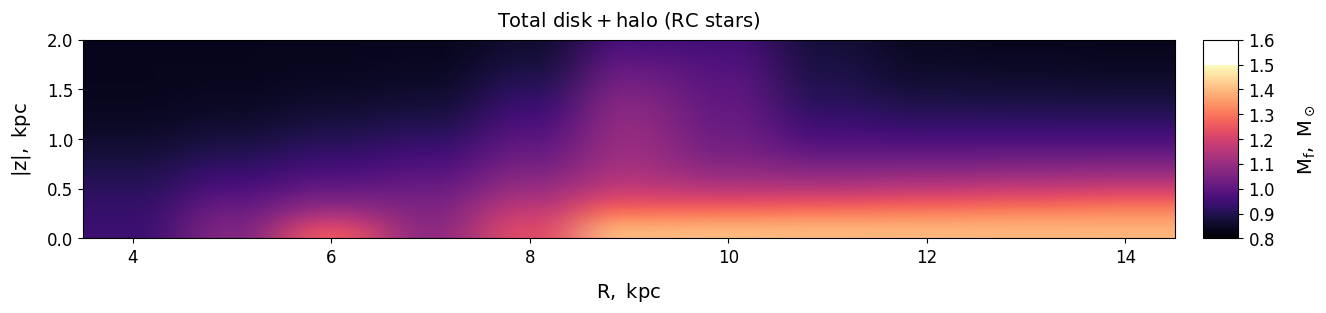

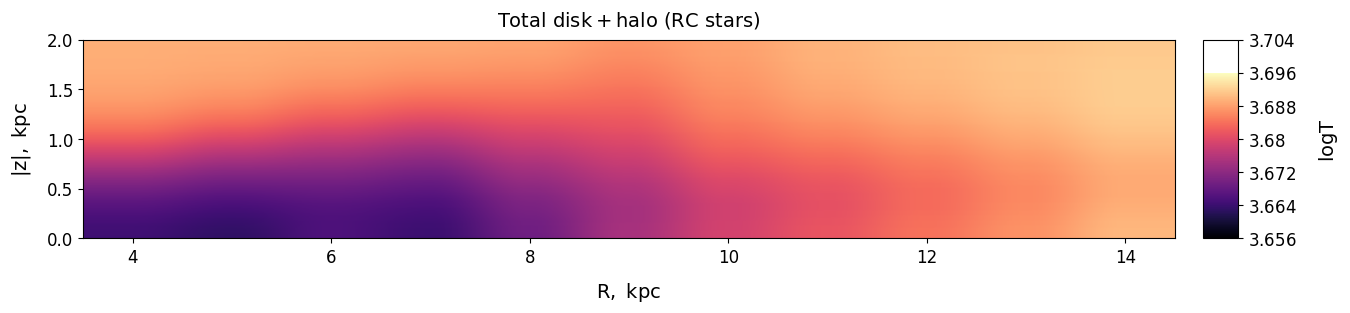

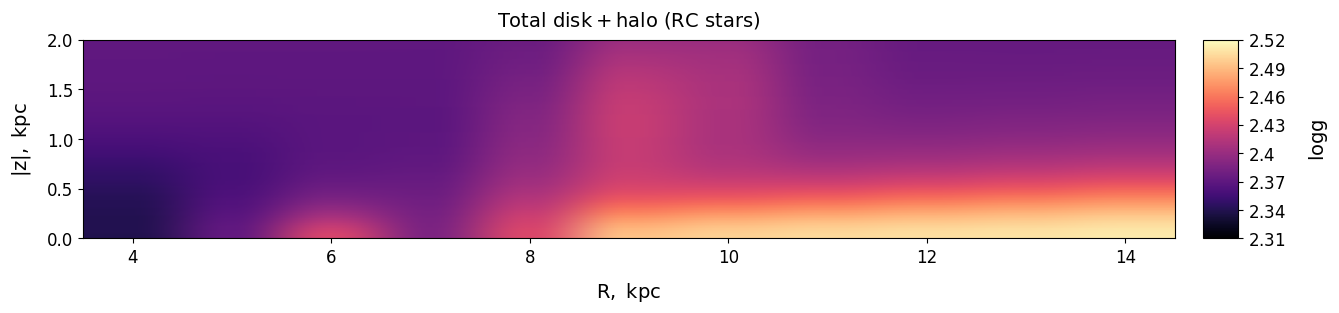

In [13]:

z_step = 25    # pc, default is 100 pc, but it's a bit rough

P.rz_map_plt('tot',mode_pop='f',number=True,dz=z_step,**kw) 
P.rz_map_plt('tot',mode_pop='wd',number=True,dz=z_step,**kw) 

# Compare to other populations:
P.rz_map_plt('tot',mode_pop='rc',number=True,dz=z_step,**kw) 
P.rz_map_plt('tot',mode_pop='gdw',number=True,dz=z_step,**kw) 

# Age, metallicity, and W-velocity dispersion can be also plotted on Rz-maps:
P.rz_map_quantity_plt('tot','FeH',mode_pop='rc',dz=z_step,**kw)
P.rz_map_quantity_plt('tot','age',mode_pop='rc',dz=z_step,**kw)
P.rz_map_quantity_plt('tot','sigw',mode_pop='rc',dz=z_step,**kw)

# In general, any quantity available in the SA tables can be plotted this way:
P.rz_map_quantity_plt('tot','Mf',mode_pop='rc',dz=z_step,**kw)
P.rz_map_quantity_plt('tot','logT',mode_pop='rc',dz=z_step,**kw)
P.rz_map_quantity_plt('tot','logg',mode_pop='rc',dz=z_step,**kw)


#### Hess diagrams

Volume spanning though these R-bins:[7. 8. 9.]


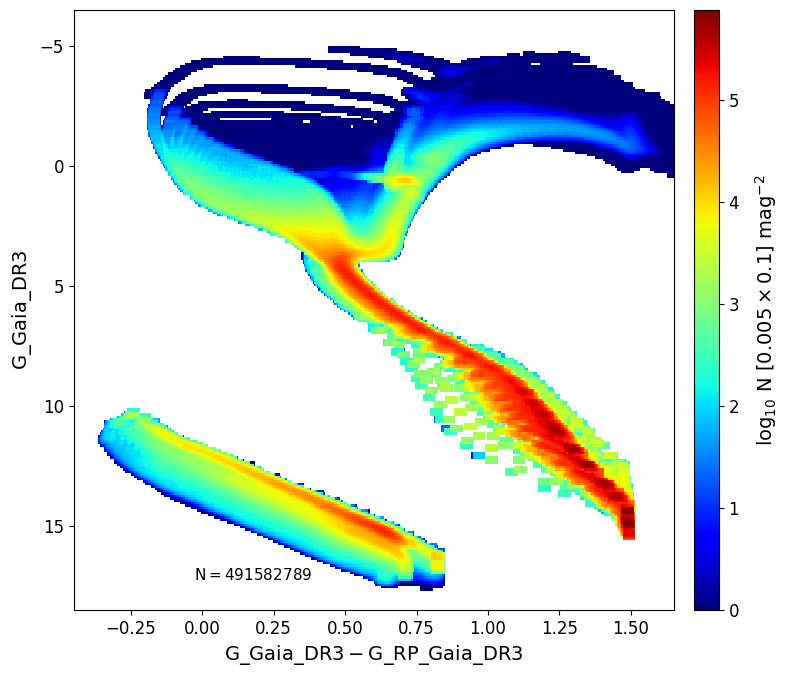

In [5]:

kw = {'mode_iso':mode_iso}


P.hess_simple_plt(
    'tot',
    'rphiz_box',
    ['G_Gaia_DR3','G_Gaia_DR3','G_RP_Gaia_DR3'],
    [[-0.45,1.65],[-6.5,18.5]],
    [0.005,0.1],
    smooth=[0.05,0.3],
    R_minmax=[p.Rsun - 1,p.Rsun + 1],
    zlim=[0,300],
    dphi=45,
    **kw
    );

'''
P.hess_simple_plt(
    'tot',
    'local_sphere',
    ['G_Gaia_DR3','G_Gaia_DR3','G_RP_Gaia_DR3'],
    [[-0.45,1.65],[-5,18.5]],
    [0.005,0.1],
    smooth=[0.05,0.3],
    r_minmax=[0,100],
    **kw
    );
''';

#### Automated plotting

In [6]:
# And let's produce and save these plots automatically:

z_slices = np.arange(0, p.zmax, 200)        # pc
age_bins = np.arange(0, tp + 0.5, 0.5)      # Gyr
met_bins = np.arange(-0.8, 0.55, 0.05)      # dex
sigma_age = 0.1                             # Gyr
sigma_met = 0.1                             # dex
rmax = 100                                  # pc

PB = PlotBlocks(p,a,inp)
PB.basic_output(z_slices,age_bins,met_bins,sigma_age,sigma_met,rmax,**kw)    



Plotting block of figures for the JJ model... 
Input                     :  	ok 
Potential                 :  	ok 
Scale heights             :  	ok 
Densities                 :  	ok 
Ages                      :  	ok 
Metallicities             :  	ok 
Kinematics                :  	ok 
Populations               :  Volume spanning though these R-bins:[8.]
Volume spanning though these R-bins:[8.]
Volume spanning though these R-bins:[8. 9.]
	ok 
RZ-maps                   :  rz_map_plt: Unnecessary input. Keyword 'mode_iso' works only with 'mode_pop'.
rz_map: Unnecessary input. Keyword 'mode_iso' works only with 'mode_pop'.
rhoz_monoage: Unnecessary input. Keyword 'mode_iso' works only with 'mode_pop'.
rhoz_monoage: Unnecessary input. Keyword 'mode_iso' works only with 'mode_pop'.
rhoz_monoage: Unnecessary input. Keyword 'mode_iso' works only with 'mode_pop'.
rhoz_monoage: Unnecessary input. Keyword 'mode_iso' works only with 'mode_pop'.
rhoz_monoage: Unnecessary input. Keyword 'mode_iso' w